# Schedules and Gradient Clipping: Do They Actually Help?

**AIGC 5500 — Week 2, Part 4 — "Try it" exercise**

Takes Part 3's best-performing optimizer (SGD with momentum) and adds a
`CosineAnnealingLR` schedule and gradient clipping, exactly as the
exercise asks — then checks honestly whether either one helped, rather
than assuming they must have. It then applies the same two tools to
AdamW, which is where Part 3 actually found a problem for them to fix.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## The network and task

The same corrected network and toy regression task as Parts 2 and 3, so
every result in this notebook is directly comparable to what came before.

In [ ]:
class DeepSigmoidNet(nn.Module):
    def __init__(self, depth, width=32, in_features=32):
        super().__init__()
        linears, norms = [], []
        n_in = in_features
        for _ in range(depth):
            linears.append(nn.Linear(n_in, width))
            norms.append(nn.BatchNorm1d(width))
            n_in = width
        self.linears = nn.ModuleList(linears)
        self.norms = nn.ModuleList(norms)
        self.out = nn.Linear(width, 1)
        for layer in self.linears:
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for linear, norm in zip(self.linears, self.norms):
            x = torch.sigmoid(norm(linear(x)))
        return self.out(x)


def make_toy_regression(n=256, in_features=32, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, in_features, generator=g)
    true_w = torch.randn(in_features, 1, generator=g)
    noise = 0.1 * torch.randn(n, 1, generator=g)
    y = x @ true_w * 0.3 + noise
    return x, y

## A training loop with an optional schedule and optional clipping

Gradient clipping happens after `backward()` and before `step()` — it
rescales the gradients already sitting in `.grad`. `clip_grad_norm_`
returns the *pre-clip* gradient norm, which lets us record how large the
gradient actually was and whether clipping engaged, not just whether we
asked for it.

In [ ]:
def make_optimizer(name, params, lr):
    if name == "SGD+momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "AdamW":
        return torch.optim.AdamW(params, lr=lr)
    raise ValueError(name)


def train(depth, optimizer_name, lr, epochs, use_schedule, clip_norm, seed=0):
    torch.manual_seed(seed)
    model = DeepSigmoidNet(depth=depth)
    x, y = make_toy_regression(seed=0)
    opt = make_optimizer(optimizer_name, model.parameters(), lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if use_schedule else None

    history, raw_grad_norms, clipped_epochs = [], [], 0
    for epoch in range(epochs):
        opt.zero_grad()                                   # 1. clear old gradients
        preds = model(x)                                  # 2. forward pass
        loss = nn.functional.mse_loss(preds, y)            # 3. compute the loss
        loss.backward()                                    # 4. backward pass

        # clip_grad_norm_ returns the norm BEFORE clipping, so we can
        # tell how large the raw gradient was even when clip_norm=None
        # (using a very large ceiling that never actually clips).
        ceiling = clip_norm if clip_norm is not None else 1e9
        raw_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=ceiling).item()
        raw_grad_norms.append(raw_norm)
        if clip_norm is not None and raw_norm > clip_norm:
            clipped_epochs += 1

        opt.step()                                         # 5. update parameters
        if sched is not None:
            sched.step()
        history.append(loss.item())

    return {"loss": history, "raw_grad_norms": raw_grad_norms, "clipped_epochs": clipped_epochs}

## First: apply it to Part 3's winner, SGD with momentum

This is the exercise as written — take the best-performing optimizer
and add both tools.

In [ ]:
depth, lr, epochs = 20, 0.01, 150

sgd_baseline = train(depth, "SGD+momentum", lr, epochs, use_schedule=False, clip_norm=None)
sgd_fixed    = train(depth, "SGD+momentum", lr, epochs, use_schedule=True,  clip_norm=1.0)

print(f"SGD+momentum, constant lr, no clipping   — last-10-epoch mean loss: {sum(sgd_baseline['loss'][-10:])/10:.5f}")
print(f"SGD+momentum, cosine schedule + clipping — last-10-epoch mean loss: {sum(sgd_fixed['loss'][-10:])/10:.5f}")
print(f"Max raw gradient norm seen (baseline): {max(sgd_baseline['raw_grad_norms']):.3f}")
print(f"Epochs where clipping actually engaged (fixed run): {sgd_fixed['clipped_epochs']} / {epochs}")

SGD+momentum, constant lr, no clipping   — last-10-epoch mean loss: 0.00092
SGD+momentum, cosine schedule + clipping — last-10-epoch mean loss: 0.01312
Max raw gradient norm seen (baseline): 2.308
Epochs where clipping actually engaged (fixed run): 31 / 150


Run this and the scheduled-and-clipped version does *not* win — its
final loss is noticeably worse than the plain constant-rate baseline.
That is a real result, not a mistake in this notebook, and it is worth
sitting with rather than dismissing.

**Why:** clipping does engage here too — the table above will show it
firing in a real fraction of epochs, not zero. But look at the *size* of
the raw gradient it is clipping: the baseline's max raw gradient norm
tops out modestly above the 1.0 threshold, nowhere near the sharper
spikes you will see from AdamW below. Clipping a gradient that was only
slightly too large removes a small, mostly harmless step; it is not
fixing a real instability, because SGD+momentum did not have one here
(consistent with Part 3, where this was the one optimizer that never
spiked). The schedule is doing most of the damage in this run: it takes
away learning rate the run still needed, since SGD+momentum was still
making steady progress with a constant rate all the way to epoch 150.

## Second: apply the same tools to AdamW

Part 3 found a real problem here — periodic loss spikes. This is the
case a schedule and clipping actually target.

In [ ]:
adamw_baseline = train(depth, "AdamW", lr, epochs, use_schedule=False, clip_norm=None)
adamw_fixed    = train(depth, "AdamW", lr, epochs, use_schedule=True,  clip_norm=1.0)

print(f"AdamW, constant lr, no clipping   — last-10-epoch mean loss: {sum(adamw_baseline['loss'][-10:])/10:.5f}")
print(f"AdamW, cosine schedule + clipping — last-10-epoch mean loss: {sum(adamw_fixed['loss'][-10:])/10:.5f}")
print(f"Max raw gradient norm seen (baseline): {max(adamw_baseline['raw_grad_norms']):.3f}")
print(f"Epochs where clipping actually engaged (fixed run): {adamw_fixed['clipped_epochs']} / {epochs}")

def count_spikes(history, factor=1.5):
    return sum(1 for i in range(1, len(history)) if history[i] > history[i - 1] * factor)

print(f"\nSpikes (epoch-to-epoch jump > 1.5x) — baseline: {count_spikes(adamw_baseline['loss'])}   "
      f"scheduled+clipped: {count_spikes(adamw_fixed['loss'])}")

AdamW, constant lr, no clipping   — last-10-epoch mean loss: 0.00996
AdamW, cosine schedule + clipping — last-10-epoch mean loss: 0.00680
Max raw gradient norm seen (baseline): 4.322
Epochs where clipping actually engaged (fixed run): 44 / 150

Spikes (epoch-to-epoch jump > 1.5x) — baseline: 17   scheduled+clipped: 8


This time the tools earn their place: clipping engages in a real
fraction of epochs (the raw gradient norm exceeds 1.0 often enough to
matter), the spike count drops, and the final loss improves. The
difference between this result and SGD+momentum's is not a contradiction
— it is the actual lesson. Gradient clipping only does something on
gradients large enough to clip, and a schedule only helps a run that was
actually going to benefit from a smaller rate later. Neither tool is a
free win; each targets a specific failure mode, and that failure mode
has to be present for the tool to have any effect.

## Plot both comparisons side by side

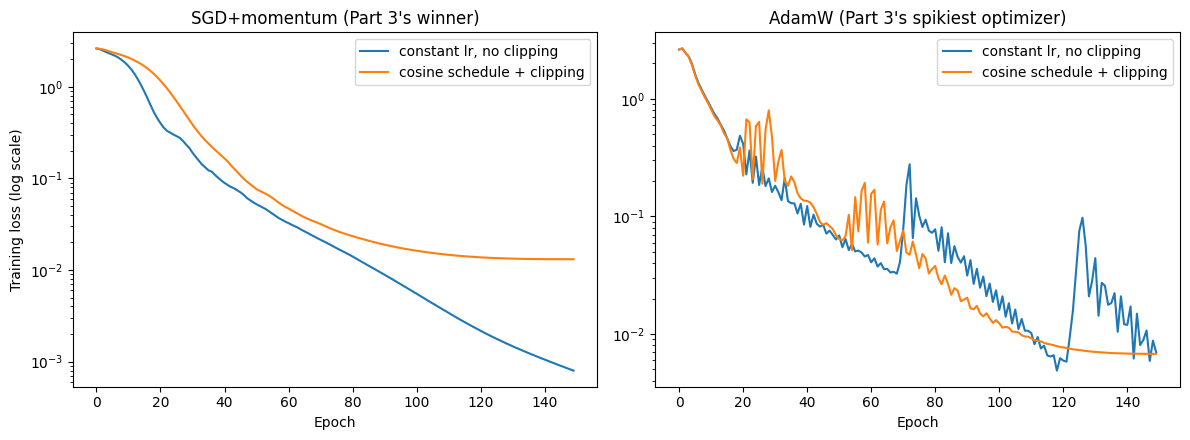

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(sgd_baseline["loss"], label="constant lr, no clipping")
axes[0].plot(sgd_fixed["loss"], label="cosine schedule + clipping")
axes[0].set_yscale("log")
axes[0].set_title("SGD+momentum (Part 3's winner)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss (log scale)")
axes[0].legend()

axes[1].plot(adamw_baseline["loss"], label="constant lr, no clipping")
axes[1].plot(adamw_fixed["loss"], label="cosine schedule + clipping")
axes[1].set_yscale("log")
axes[1].set_title("AdamW (Part 3's spikiest optimizer)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("schedule_clipping_comparison.png", dpi=150)
plt.show()

## A look at mixed precision and gradient accumulation

Neither needs a live demo the way clipping does — there is no
"gradient norm" style number to inspect, and mixed precision's benefit
is speed and memory on a GPU, which this notebook cannot show on CPU.
The shape of the code is what matters:

```python
scaler = torch.cuda.amp.GradScaler()

with torch.autocast(device_type="cuda", dtype=torch.float16):
    preds = model(x)
    loss = criterion(preds, y)

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()
```

Gradient accumulation solves an unrelated problem — a batch too large
for memory — by summing gradients across several smaller forward/backward
passes before calling `optimizer.step()` once:

```python
optimizer.zero_grad()
for micro_batch in split_into_micro_batches(batch, n=4):
    preds = model(micro_batch.x)
    loss = criterion(preds, micro_batch.y) / 4     # average, not sum
    loss.backward()                                 # gradients accumulate here
optimizer.step()
```

## Takeaway

The Try it exercise asks you to compare a scheduled-and-clipped run
against Part 3's unscheduled one — it does not promise the new run will
win, and here, for the already-smooth optimizer, it does not. Its point
was never that these two tools always help. It is that late-training
tools have to be matched to a late-training problem that is actually
present, and the only way to know if it is present is to compare, as
this notebook does, rather than to add every tool by default and assume
the loss curve improved because you did.